In [ ]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
from torch.utils.data import DataLoader, TensorDataset
import seaborn as sns
import matplotlib.pyplot as plt
import joblib

In [ ]:
import os
print(os.getcwd())
!dir   # Windows

In [ ]:
!jupyter nbconvert --to script test.ipynb

In [ ]:

X_test = joblib.load('/content/X_test_prob.pkl')
y_test = joblib.load('/content/y_test_enc.pkl')

#TEST: MLP

In [4]:
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
test_loader_mlp = DataLoader(test_dataset, batch_size=32, shuffle=True)

In [10]:
class MLP(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.25),

            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(128, num_classes)
        )
    def forward(self, x):
        return self.net(x)

In [12]:
model = joblib.load('/content/mlp_model.joblib')
model.eval()

MLP(
  (net): Sequential(
    (0): Linear(in_features=1500, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.25, inplace=False)
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=128, out_features=10, bias=True)
  )
)

In [13]:
with torch.no_grad():
    outputs = model(X_test_tensor)
    predictions = torch.argmax(outputs, dim=1)

In [28]:
from sklearn.metrics import classification_report, f1_score,jaccard_score,confusion_matrix
print(classification_report(predictions,y_test))

              precision    recall  f1-score   support

           0       0.94      0.95      0.95       714
           1       0.84      0.90      0.87        70
           2       0.85      0.88      0.86       157
           3       0.98      0.94      0.96      1234
           4       0.58      0.70      0.64        30
           5       0.82      0.81      0.81       155
           6       0.68      0.82      0.75       137
           7       0.75      0.86      0.80        77
           8       0.84      0.80      0.82       167
           9       0.89      0.89      0.89        64

    accuracy                           0.91      2805
   macro avg       0.82      0.85      0.83      2805
weighted avg       0.91      0.91      0.91      2805



In [51]:
f1_MLP=f1_score(predictions,y_test,average='macro')
print(f1_MLP)

0.8343740471993641


In [52]:
jac_MLP=jaccard_score(predictions,y_test,average='macro')
print(jac_MLP)

0.7256973374089102


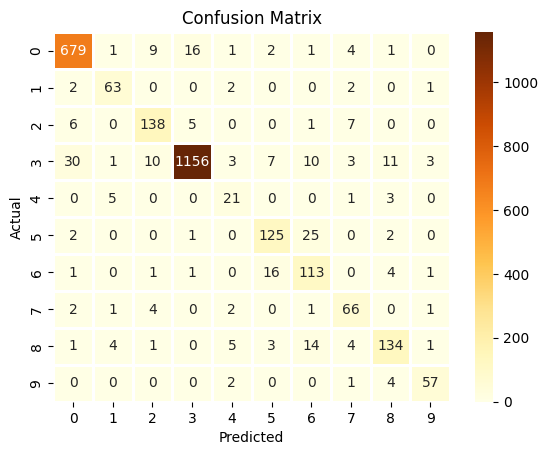

In [44]:
cf=confusion_matrix(predictions,y_test,)
# plt.figure(figsize=(10,10))
sns.heatmap(cf,annot=True,fmt='g',cmap="YlOrBr",linewidths=2)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# TEST: LinearSVC

In [21]:
model = joblib.load('/content/LinearSVC_model.pkl')

In [22]:
y_pred=model.predict(X_test)

In [23]:
print(classification_report(y_pred,y_test))

              precision    recall  f1-score   support

           0       0.96      0.84      0.89       829
           1       0.83      0.90      0.86        69
           2       0.85      0.86      0.85       160
           3       0.95      0.97      0.96      1147
           4       0.53      0.70      0.60        27
           5       0.71      0.82      0.76       131
           6       0.74      0.72      0.73       169
           7       0.60      0.95      0.74        56
           8       0.81      0.83      0.82       155
           9       0.89      0.92      0.90        62

    accuracy                           0.89      2805
   macro avg       0.79      0.85      0.81      2805
weighted avg       0.90      0.89      0.89      2805



In [45]:
f1_svm=f1_score(y_pred,y_test,average='macro')
print(f1_svm)

0.8120385022746366


In [47]:
jac_svm=jaccard_score(y_pred,y_test,average='macro')
print(jac_svm)

0.6951895058433725


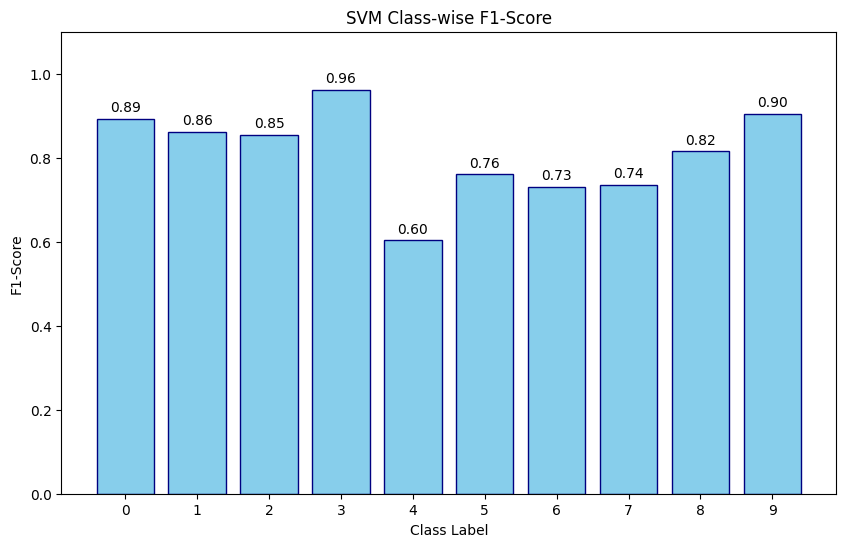

In [72]:

report_dict = classification_report(y_test, y_pred, output_dict=True)

# 2. Get your unique classes
classes = np.unique(y_test)

# 3. Extract scores (converting cls to string to match dictionary keys)
f1_scores = [report_dict[str(cls)]['f1-score'] for cls in classes]

# 4. Create the plot
plt.figure(figsize=(10, 6))
# If classes are [0, 1, 2], plt.bar handles them fine as x-axis ticks
bars = plt.bar(classes, f1_scores, color='skyblue', edgecolor='navy')

# Formatting for a professional look
plt.xticks(classes) # Ensures every class gets a tick mark
plt.xlabel('Class Label')
plt.ylabel('F1-Score')
plt.title('SVM Class-wise F1-Score')
plt.ylim(0, 1.1)

# Add value labels on top of bars
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.01, f'{yval:.2f}', ha='center', va='bottom')

plt.show()

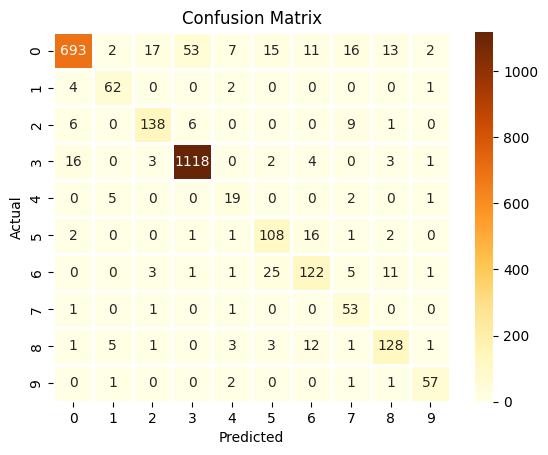

In [54]:
cf=confusion_matrix(y_pred,y_test,)
# plt.figure(figsize=(10,10))
sns.heatmap(cf,annot=True,fmt='g',cmap="YlOrBr",linewidths=2)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Compare SVM Vs MLP

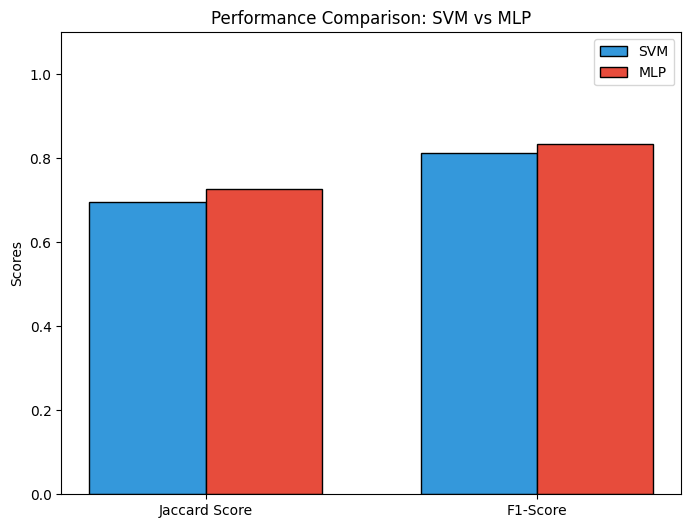

In [53]:
# Data setup
labels = ['Jaccard Score', 'F1-Score']
svm_scores = [jac_svm, f1_svm]
mlp_scores = [jac_MLP, f1_MLP]

x = np.arange(len(labels))  # The label locations
width = 0.35                # The width of the bars

# Create the plot
fig, ax = plt.subplots(figsize=(8, 6))
rects1 = ax.bar(x - width/2, svm_scores, width, label='SVM', color='#3498db', edgecolor='black')
rects2 = ax.bar(x + width/2, mlp_scores, width, label='MLP', color='#e74c3c', edgecolor='black')

# Add labels, title and axes ticks
ax.set_ylabel('Scores')
ax.set_title('Performance Comparison: SVM vs MLP')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 1.1)  # Scores are typically between 0 and 1
ax.legend()